In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.features import (
    build_features, get_feature_columns, CATEGORICAL_FEATURES,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

raw = pd.read_parquet("../data/processed/loans_model.parquet")
df = build_features(raw)

feature_columns = get_feature_columns(df)

print("Before:", raw.shape)
print("After: ", df.shape)
print("Number of features:", len(feature_columns))

Before: (618584, 72)
After:  (618584, 71)
Number of features: 62


In [2]:
checks = {
    "annual_inc == 0": (df["annual_inc"] == 0).sum(),
    "dti >= 999": (df["dti"] >= 999).sum(),
    "total_rev_hi_lim >= 9,999,999": (df["total_rev_hi_lim"] >= 9_999_999).sum(),
    "infinite values": df[feature_columns].select_dtypes("number").isin([float("inf"), float("-inf")]).sum().sum(),
}
pd.Series(checks, name="rows")

annual_inc == 0                  0
dti >= 999                       0
total_rev_hi_lim >= 9,999,999    0
infinite values                  0
Name: rows, dtype: int64

In [3]:
new_features = [
    "fico_avg", "emp_length_years", "emp_length_missing",
    "credit_history_months", "loan_to_income", "total_bal_to_limit",
]
df[new_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
fico_avg,618584.0,697.11,31.15,627.0,672.00,692.00,712.00,847.50
emp_length_years,582445.0,5.85,3.67,0.0,2.00,6.00,10.00,10.00
emp_length_missing,618584.0,0.06,0.23,0.0,0.00,0.00,0.00,1.00
credit_history_months,618584.0,193.02,91.10,36.0,131.00,175.00,239.00,852.00
loan_to_income,618582.0,0.20,0.11,0.0,0.11,0.18,0.27,10.00
total_bal_to_limit,566923.0,0.72,0.20,0.0,0.60,0.77,0.87,9.02


In [4]:
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}: {df[col].nunique()} categories")
    print(df[col].value_counts().tail(5))


home_ownership: 4 categories
home_ownership
MORTGAGE    287274
RENT        268253
OWN          62880
OTHER          177
Name: count, dtype: int64

verification_status: 3 categories
verification_status
Source Verified    217766
Not Verified       215601
Verified           185217
Name: count, dtype: int64

purpose: 12 categories
purpose
car         6902
moving      4622
vacation    4312
house       2576
wedding     1903
Name: count, dtype: int64

addr_state: 47 categories
addr_state
AK       1556
OTHER    1426
WY       1371
SD       1279
VT       1237
Name: count, dtype: int64


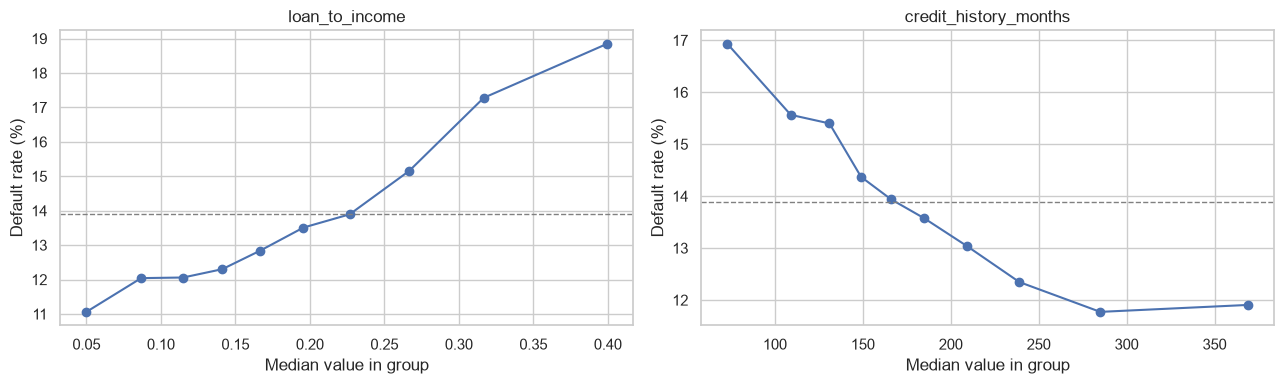

In [5]:
overall_rate = df["target"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ["loan_to_income", "credit_history_months"]):
    bins = pd.qcut(df[col], q=10, duplicates="drop")
    grouped = df.groupby(bins, observed=True).agg(
        median_value=(col, "median"),
        default_rate=("target", "mean"),
    )
    ax.plot(grouped["median_value"], grouped["default_rate"] * 100, marker="o")
    ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Median value in group")
    ax.set_ylabel("Default rate (%)")

plt.tight_layout()
plt.savefig("../results/figures/default_rate_new_features.png", dpi=120)
plt.show()

In [6]:
applicant = raw.iloc[[0]].copy()
print(build_features(applicant)[new_features])

   fico_avg  emp_length_years  emp_length_missing  credit_history_months  \
0     737.0                 0                   0                    186   

   loan_to_income  total_bal_to_limit  
0        0.294118                 NaN  
